In [1]:
import sys,os
from copy import copy
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns
import numpy as np
import pandas as pd

import scanpy as sc
import anndata
from scib_metrics.benchmark import Benchmarker


import warnings
warnings.filterwarnings('ignore')


mpl.rcParams['figure.dpi'] = 50
mpl.rcParams['pdf.fonttype'] = 42
sc.settings.set_figure_params(facecolor=(0, 0, 0, 0), dpi=50, dpi_save=600)

sns.set_style({'axes.grid': False})

In [19]:
project_dir = '/home/xuq44/projects/scPDAC'
sc.settings.figdir = f'{project_dir}/figures/'
fig_dir = f'{project_dir}/figures/'


gns = copy(mpl.cm.Blues)
gns.set_under("lightgray")

plate_level_all0 = pd.read_csv(f"{project_dir}/data/db/pdac_color.txt",
                               sep='\t', header=None, index_col=0)
plate_level_all = plate_level_all0.to_dict()[1]
plate_level_all['nan'] = 'lightgray'



In [3]:
py_methods = ['mergepy', 'harmonypy', 'bbknn', 'combat', 'csspearson', 'cssspearman']
py_method2s = ['scanvi', 'scpoli']
r_methods = ['seurat3', 'seurat4', 'seurat5']


In [10]:
for inti_method in ['mergepy', 'harmonypy', 'bbknn', 'combat', 'csspearson', 'cssspearman',
                    'scanvi', 'scpoli']:

    adata0 = sc.read_h5ad(f"{project_dir}/results/run_20241130_scp/all/other_methods/pdac_{inti_method}_integration.h5ad")
    sc.pl.umap(adata0, color=['level_1', 'level_2'], wspace=0.6, size=10, ncols=2, 
               frameon=False, palette=plate_level_all, save='_benchmark_pca.pdf')



In [ ]:

adata = sc.read_h5ad(f"{project_dir}/results/run_20241130_scp/all/other_methods/pdac_all_integration.h5ad")

adata0 = sc.read_h5ad(f"{project_dir}/results/run_20241130_scp/all/other_methods/pdac_harmonypy_integration.h5ad")
adata.obsm['X_harmony'] = adata0.obsm['X_pca_harmony']

adata0 = sc.read_h5ad(f"{project_dir}/results/run_20241130_scp/all/other_methods/pdac_scpoli_integration.h5ad")
adata.obsm['X_scPoli'] = adata0.obsm['X_scPoli']

adata0 = sc.read_h5ad(f"{project_dir}/results/run_20241130_scp/all/other_methods/pdac_bbknn_integration.h5ad")
adata.obsm['X_bbknn'] = adata0.obsm['X_pca']

adata0 = sc.read_h5ad(f"{project_dir}/results/run_20241130_scp/all/other_methods/pdac_cssspearman_integration.h5ad")
adata.obsm['X_cssspearman'] = adata0.obsm['X_corr']

adata0 = sc.read_h5ad(f"{project_dir}/results/run_20241130_scp/all/other_methods/pdac_csspearson_integration.h5ad")
adata.obsm['X_csspearson'] = adata0.obsm['X_corr']

adata0 = sc.read_h5ad(f"{project_dir}/results/run_20241130_scp/all/other_methods/pdac_scanvi_integration.h5ad")
adata.obsm['X_scANVI'] = adata0.obsm['X_scANVI']
adata.obsm['X_scVI'] = adata0.obsm['X_scVI']


adata.write_h5ad(f"{project_dir}/results/run_20241130_scp/all/other_methods/pdac_all_integration.h5ad", compression="gzip")


In [26]:
adata = sc.read_h5ad(f"{project_dir}/results/run_20241130_scp/all/other_methods/pdac_all_integration.h5ad")


In [94]:
seu4 = pd.read_csv(f"{project_dir}/results/run_20241130_scp/all/pdac_seurat4_integration_pcs2.txt", sep='\t')
sub_adata = adata[seu4.index.tolist()]
sub_adata.obsm['X_seurat4'] = seu4.to_numpy()

seu5 = pd.read_csv(f"{project_dir}/results/run_20241130_scp/all/pdac_seurat5_integration_pcs2.txt", sep='\t')
sub_adata.obsm['X_seurat5'] = seu5.to_numpy()

seu3 = pd.read_csv(f"{project_dir}/results/run_20241130_scp/all/pdac_seurat3_integration_pcs2.txt", sep='\t')
sub_adata.obsm['X_seurat3'] = seu3.to_numpy()


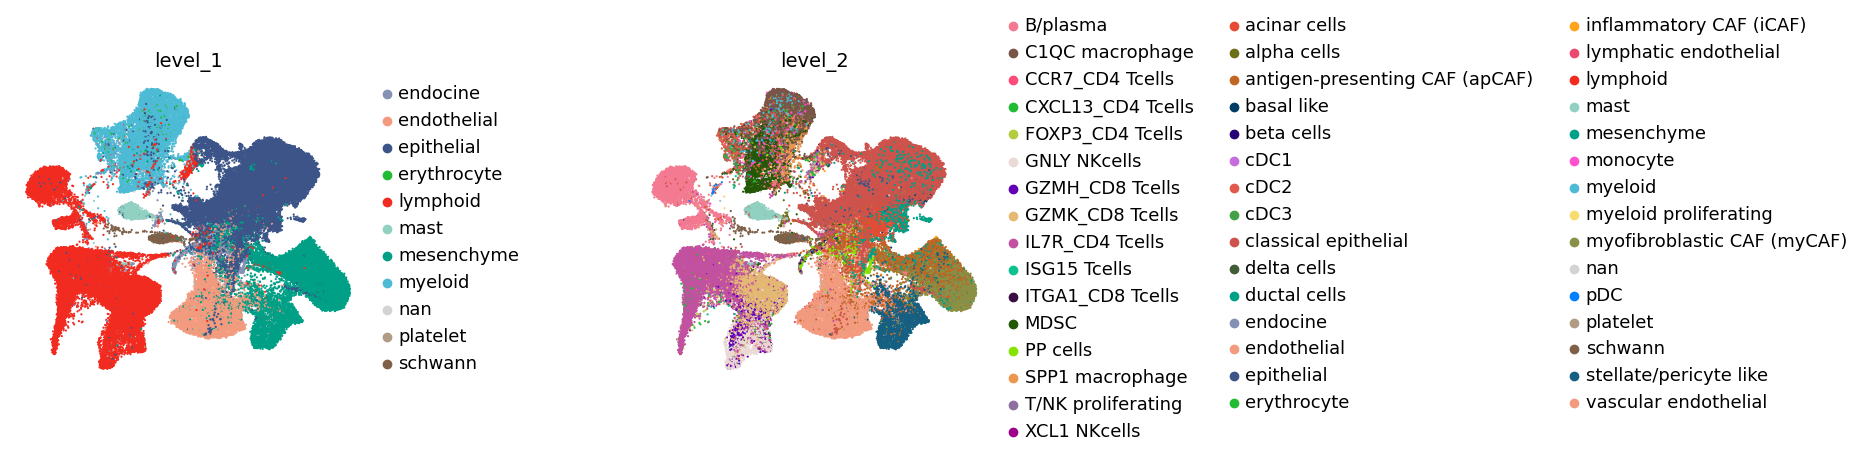

In [114]:
sc.pp.neighbors(sub_adata, n_neighbors=15,
                n_pcs=len(sub_adata.obsm['X_seurat3'][0]), 
                use_rep='X_seurat3')
sc.tl.umap(sub_adata)

sc.pl.umap(sub_adata, color=['level_1', 'level_2'], wspace=0.6, size=10, ncols=2, 
           frameon=False, palette=plate_level_all, save='seurat3_benchmark_pca.pdf')




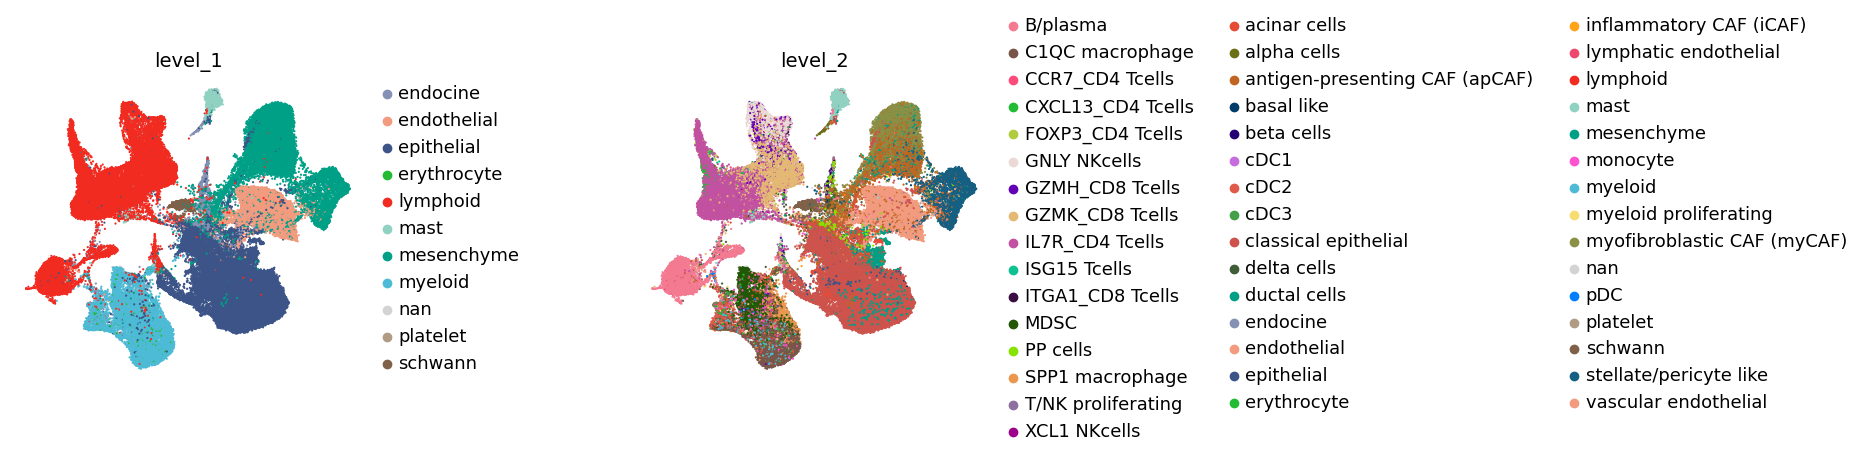

In [105]:
sc.pp.neighbors(sub_adata, n_neighbors=15,
                n_pcs=len(sub_adata.obsm['X_seurat5'][0]), 
                use_rep='X_seurat5')
sc.tl.umap(sub_adata)

sc.pl.umap(sub_adata, color=['level_1', 'level_2'], wspace=0.6, size=10, ncols=2, 
           frameon=False, palette=plate_level_all, save='seurat5_benchmark_pca.pdf')




In [115]:
all_res = pd.DataFrame()

for seed in range(10):
    adata0 = sc.pp.subsample(sub_adata, n_obs=10000, copy=True, random_state=seed)

    bm = Benchmarker(
        adata0,
        batch_key="sample_id",
        label_key="level_1",
        embedding_obsm_keys=["X_pca", 
                             "X_harmony", 
                             "X_scPoli", 
                             "X_scVI", 
                             "X_scANVI", 
                             "X_combat", 
                             'X_bbknn',
                             'X_cssspearman',
                             'X_csspearson',
                             'X_seurat3',
                             'X_seurat4',
                             'X_seurat5'
                            ],
        n_jobs=-1,
    )
    bm.benchmark()
    res_df = bm.get_results(min_max_scale=True)
    res_df['seed'] = seed
    all_res = pd.concat([all_res,res_df])

all_res = all_res[all_res.Total!='Aggregate score'].reset_index()
all_res['Embedding2'] = [i.split('_')[-1] for i in all_res.Embedding]


Metrics:  60%|██████    | 6/10 [00:17<00:06,  1.59s/it, Batch correction: kbet_per_label]

INFO     erythrocyte consists of a single batch or is too small. Skip.                                             
INFO     platelet consists of a single batch or is too small. Skip.                                                



Metrics:   0%|          | 0/10 [00:00<?, ?it/s]
                                                                                         
Metrics:  60%|██████    | 6/10 [00:14<00:05,  1.28s/it, Batch correction: kbet_per_label]

INFO     erythrocyte consists of a single batch or is too small. Skip.                                             
INFO     platelet consists of a single batch or is too small. Skip.                                                



Metrics:   0%|          | 0/10 [00:00<?, ?it/s]
                                                                                         
Metrics:  60%|██████    | 6/10 [00:02<00:01,  3.79it/s, Batch correction: kbet_per_label]

INFO     erythrocyte consists of a single batch or is too small. Skip.                                             
INFO     platelet consists of a single batch or is too small. Skip.                                                


... (231 outputs left out)

INFO     erythrocyte consists of a single batch or is too small. Skip.                                             
INFO     nan consists of a single batch or is too small. Skip.                                                     



Metrics:   0%|          | 0/10 [00:00<?, ?it/s]
                                                                                         
Metrics:  60%|██████    | 6/10 [00:12<00:05,  1.31s/it, Batch correction: kbet_per_label]

INFO     erythrocyte consists of a single batch or is too small. Skip.                                             
INFO     nan consists of a single batch or is too small. Skip.                                                     



Embeddings: 100%|██████████| 12/12 [04:10<00:00, 20.90s/it]ch correction: pcr_comparison]    

                                                                                         

In [119]:
all_res['Embedding2'] = [i.split('_')[-1] for i in all_res.Embedding]
all_res.Embedding2 = pd.Categorical(all_res.Embedding2, 
                                   categories=['pca','bbknn','cssspearman','csspearson',
                                              'harmony','combat','seurat3','seurat4','seurat5','scVI','scANVI','scPoli'], ordered=True)


In [99]:
# all_res

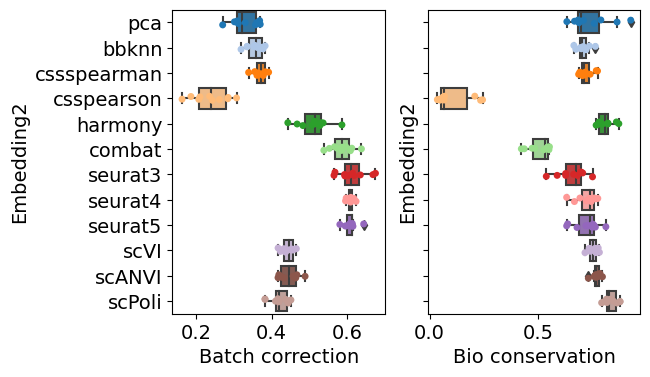

In [122]:
fig, axs = plt.subplots(1, 2, figsize=(6, 4), sharey=True)

Classic_20 = ['#1F77B4FF', '#AEC7E8FF', '#FF7F0EFF', '#FFBB78FF', 
              '#2CA02CFF', '#98DF8AFF', '#D62728FF', '#FF9896FF', 
              '#9467BDFF', '#C5B0D5FF', '#8C564BFF', '#C49C94FF', 
              '#E377C2FF', '#F7B6D2FF', '#7F7F7FFF', '#C7C7C7FF', 
              '#BCBD22FF', '#DBDB8DFF', '#17BECFFF', '#9EDAE5FF']

sns.boxplot(data=all_res, y='Embedding2', x='Batch correction', palette=Classic_20, ax=axs[0])
sns.stripplot(data=all_res, y='Embedding2', x='Batch correction', palette=Classic_20, ax=axs[0])
# axs[0].tick_params(axis='x', labelrotation=30)

sns.boxplot(data=all_res, y='Embedding2', x='Bio conservation', palette=Classic_20, ax=axs[1])
sns.stripplot(data=all_res, y='Embedding2', x='Bio conservation', palette=Classic_20, ax=axs[1])
# axs[1].tick_params(axis='x', labelrotation=30)

fig.savefig(f'{fig_dir}/benchmark_inti.pdf')


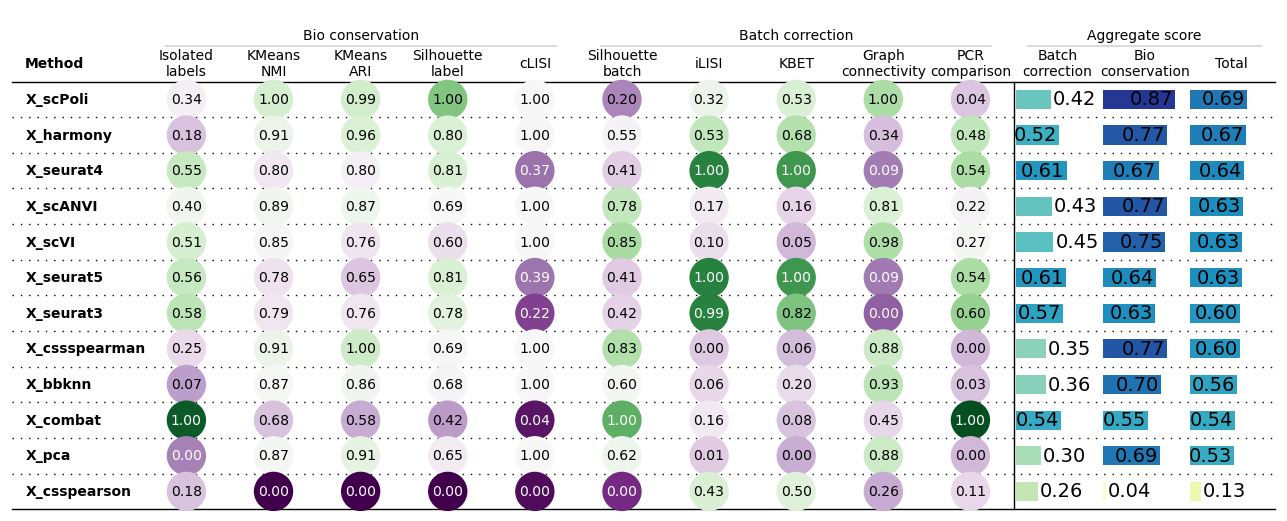

In [121]:
bm.plot_results_table(min_max_scale=True, save_dir=fig_dir)
